# Hotel Booking Analysis for Understanding Customer Behavior and Cancellation Trends

## Problem Statement
This project analyses hotel booking data to understand customer booking behaviour and identify patterns associated with booking cancellations. The analysis focuses on hotel type, lead time, pricing, market segments, customer types, stay characteristics and booking trends.

## Analysis Questions
1. What is the overall cancellation rate, and how does it differ between hotel types?
2. How are lead time and average daily rate (ADR) associated with cancellations?
3. Which market segments and customer types show the highest cancellation rates?
4. How do booking and cancellation volumes change over time?
5. How do stay characteristics and special requests differ between cancelled and non-cancelled bookings?

## Dataset
Source: https://www.kaggle.com/datasets/thedevastator/hotel-bookings-analysis

The dataset contains hotel booking records including reservation status, customer characteristics, stay details, booking channel information and pricing variables.

### Column Descriptions

| Column | Description |
|---|---|
| hotel | Hotel type |
| is_canceled | Whether the booking was cancelled (1 = cancelled, 0 = not cancelled) |
| lead_time | Days between booking and arrival |
| arrival_date_year | Arrival year |
| arrival_date_month | Arrival month |
| arrival_date_week_number | Arrival week number |
| arrival_date_day_of_month | Arrival day of month |
| stays_in_weekend_nights | Number of weekend nights booked |
| stays_in_week_nights | Number of weekday nights booked |
| adults | Number of adults |
| children | Number of children |
| babies | Number of babies |
| meal | Meal package booked |
| country | Guest country code |
| market_segment | Market segment |
| distribution_channel | Booking distribution channel |
| is_repeated_guest | Whether the guest is a repeated guest |
| previous_cancellations | Number of previous cancellations |
| previous_bookings_not_canceled | Previous bookings not cancelled |
| reserved_room_type | Reserved room type |
| assigned_room_type | Assigned room type |
| booking_changes | Number of booking changes |
| deposit_type | Deposit type |
| agent | Travel agent identifier |
| company | Company identifier |
| days_in_waiting_list | Days spent on waiting list |
| customer_type | Customer type |
| adr | Average daily rate |
| required_car_parking_spaces | Required parking spaces |
| total_of_special_requests | Number of special requests |
| reservation_status | Final reservation status |
| reservation_status_date | Date of final reservation status |


## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import cufflinks as cf
from sqlalchemy import create_engine
from IPython.display import display
from urllib.parse import quote_plus

cf.go_offline()
cf.set_config_file(offline=True)

## 2. Connect to MySQL

In [2]:
DB_HOST = "localhost"
DB_PORT = 3306
DB_USER = "hotel_user"
DB_PASSWORD = "HotelProject@2026"
DB_NAME = "hotel_booking_analysis"
TABLE_NAME = "hotel_bookings"

password = quote_plus(DB_PASSWORD)

engine = create_engine(
    f"mysql+pymysql://{DB_USER}:{password}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

with engine.connect() as connection:
    print("MySQL connection successful.")

MySQL connection successful.


## 3. Load and Verify Data from MySQL

In [3]:
df = pd.read_sql(f"SELECT * FROM {TABLE_NAME}", engine)

row_count = pd.read_sql(
    f"SELECT COUNT(*) AS total_rows FROM {TABLE_NAME}",
    engine
)
display(row_count)

sample_rows = pd.read_sql(
    f"SELECT * FROM {TABLE_NAME} LIMIT 5",
    engine
)
display(sample_rows)

null_query = "SELECT " + ", ".join(
    [f"SUM(`{col}` IS NULL) AS `{col}`" for col in df.columns]
) + f" FROM {TABLE_NAME}"

sql_null_counts = pd.read_sql(null_query, engine).T
sql_null_counts.columns = ["null_count"]
display(sql_null_counts)

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")

,total_rows
0,119390


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,None,0,Transient,0.0,0,0,Check-Out,2015-01-07
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,None,0,Transient,0.0,0,0,Check-Out,2015-01-07
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,None,0,Transient,75.0,0,0,Check-Out,2015-02-07
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,None,0,Transient,75.0,0,0,Check-Out,2015-02-07
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,None,0,Transient,98.0,0,1,Check-Out,2015-03-07


,null_count
hotel,0.0
is_canceled,0.0
lead_time,0.0
arrival_date_year,0.0
arrival_date_month,0.0
arrival_date_week_number,0.0
arrival_date_day_of_month,0.0
stays_in_weekend_nights,0.0
stays_in_week_nights,0.0
adults,0.0


Dataset shape: 119390 rows x 32 columns


## 4. Initial Data Inspection

In [4]:
display(df.head())
display(df.dtypes.to_frame("data_type"))
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-01-07
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-01-07
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-02-07
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,NaN,0,Transient,75.0,0,0,Check-Out,2015-02-07
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,NaN,0,Transient,98.0,0,1,Check-Out,2015-03-07


,data_type
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


Duplicate rows: 31994


## 5. Data Cleaning

In [5]:
required_columns = [
    "hotel", "is_canceled", "lead_time", "arrival_date_year",
    "arrival_date_month", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "country",
    "market_segment", "distribution_channel", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled",
    "deposit_type", "customer_type", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
    "reservation_status_date"
]

missing_required = [col for col in required_columns if col not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

rows_before = len(df)
duplicates_before = df.duplicated().sum()

df = df.drop_duplicates().copy()

numeric_columns = [
    "is_canceled", "lead_time", "arrival_date_year",
    "arrival_date_day_of_month", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "adr",
    "required_car_parking_spaces", "total_of_special_requests"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

for col in ["agent", "company"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype("Int64")

df["reservation_status_date"] = pd.to_datetime(
    df["reservation_status_date"],
    errors="coerce"
)

df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype("Int64").astype(str)
    + "-"
    + df["arrival_date_month"].astype(str)
    + "-"
    + df["arrival_date_day_of_month"].astype("Int64").astype(str),
    errors="coerce"
)

df = df[
    (df["adults"].fillna(0) + df["children"].fillna(0) + df["babies"].fillna(0)) > 0
].copy()

df.loc[df["adr"] < 0, "adr"] = np.nan
df["adr"] = df["adr"].fillna(df["adr"].median())

df["total_stay"] = (
    df["stays_in_weekend_nights"].fillna(0)
    + df["stays_in_week_nights"].fillna(0)
)

df["cancellation_status"] = np.where(
    df["is_canceled"] == 1,
    "Cancelled",
    "Not Cancelled"
)

outlier_summary = []

for col in ["lead_time", "adr", "total_stay"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = max(0, q1 - 1.5 * iqr)
    upper_bound = q3 + 1.5 * iqr

    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_summary.append({
        "column": col,
        "lower_bound": round(lower_bound, 2),
        "upper_bound": round(upper_bound, 2),
        "outliers_detected": int(outlier_count)
    })

    df[f"{col}_clean"] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

cleaning_summary = pd.DataFrame({
    "measure": [
        "Rows before cleaning",
        "Duplicate rows removed",
        "Rows after cleaning",
        "Remaining missing values"
    ],
    "value": [
        rows_before,
        duplicates_before,
        len(df),
        int(df.isna().sum().sum())
    ]
})

display(cleaning_summary)
display(pd.DataFrame(outlier_summary))
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values").head(10))

,measure,value
0,Rows before cleaning,119390
1,Duplicate rows removed,31994
2,Rows after cleaning,87230
3,Remaining missing values,0


,column,lower_bound,upper_bound,outliers_detected
0,lead_time,0,296.00,2394
1,adr,0,226.88,2508
2,total_stay,0,9.50,2991


,missing_values
hotel,0
required_car_parking_spaces,0
booking_changes,0
deposit_type,0
agent,0
company,0
days_in_waiting_list,0
customer_type,0
adr,0
total_of_special_requests,0


## 6. Exploratory Analysis with Pandas

In [6]:
hotel_summary = (
    df.groupby("hotel", observed=False)
      .agg(
          total_bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum"),
          average_adr=("adr", "mean"),
          average_lead_time=("lead_time", "mean")
      )
      .reset_index()
)

hotel_summary["cancellation_rate"] = (
    hotel_summary["cancellations"]
    / hotel_summary["total_bookings"]
    * 100
)

display(hotel_summary.round(2))

market_segment_summary = (
    df.groupby("market_segment", observed=False)
      .agg(
          total_bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum")
      )
      .reset_index()
)

market_segment_summary["cancellation_rate"] = (
    market_segment_summary["cancellations"]
    / market_segment_summary["total_bookings"]
    * 100
)

display(
    market_segment_summary
    .sort_values("cancellation_rate", ascending=False)
    .round(2)
)

customer_type_summary = (
    df.groupby("customer_type", observed=False)
      .agg(
          total_bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum"),
          average_adr=("adr", "mean"),
          average_special_requests=("total_of_special_requests", "mean")
      )
      .reset_index()
)

customer_type_summary["cancellation_rate"] = (
    customer_type_summary["cancellations"]
    / customer_type_summary["total_bookings"]
    * 100
)

display(
    customer_type_summary
    .sort_values("cancellation_rate", ascending=False)
    .round(2)
)

cancellation_profile = (
    df.groupby("cancellation_status", observed=False)
      .agg(
          bookings=("is_canceled", "size"),
          average_lead_time=("lead_time", "mean"),
          average_adr=("adr", "mean"),
          average_total_stay=("total_stay", "mean"),
          average_special_requests=("total_of_special_requests", "mean"),
          average_previous_cancellations=("previous_cancellations", "mean")
      )
      .reset_index()
)

display(cancellation_profile.round(2))

,hotel,total_bookings,cancellations,average_adr,average_lead_time,cancellation_rate
0,City Hotel,53274,16035,111.27,77.79,30.10
1,Resort Hotel,33956,7974,99.06,83.39,23.48


,market_segment,total_bookings,cancellations,cancellation_rate
7,Undefined,2,2,100.00
6,Online TA,51553,18242,35.38
4,Groups,4922,1332,27.06
0,Aviation,226,45,19.91
5,Offline TA/TO,13855,2057,14.85
3,Direct,11780,1737,14.75
1,Complementary,692,85,12.28
2,Corporate,4200,509,12.12


,customer_type,total_bookings,cancellations,average_adr,average_special_requests,cancellation_rate
2,Transient,71862,21661,110.30,0.73,30.14
0,Contract,3135,512,92.87,0.84,16.33
3,Transient-Party,11692,1783,87.93,0.46,15.25
1,Group,541,53,84.82,0.65,9.80


,cancellation_status,bookings,average_lead_time,average_adr,average_total_stay,average_special_requests,average_previous_cancellations
0,Cancelled,24009,105.74,117.85,4.01,0.54,0.06
1,Not Cancelled,63221,70.19,102.22,3.48,0.76,0.02


## 7. Cancellation Overview

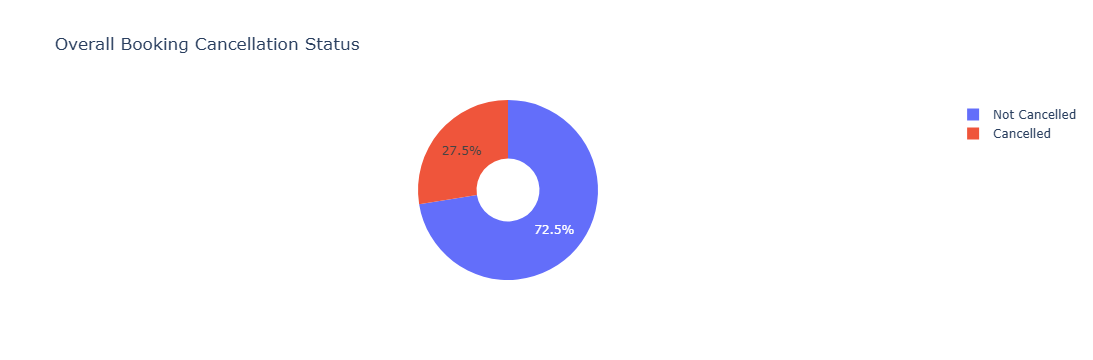

Observation: 27.52% of bookings were cancelled, while 72.48% were not cancelled.


In [7]:
status_counts = (
    df["cancellation_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="bookings")
)

fig = px.pie(
    status_counts,
    names="status",
    values="bookings",
    title="Overall Booking Cancellation Status",
    hole=0.35
)
fig.show()

overall_cancellation_rate = df["is_canceled"].mean() * 100
print(
    f"Observation: {overall_cancellation_rate:.2f}% of bookings were cancelled, "
    f"while {100 - overall_cancellation_rate:.2f}% were not cancelled."
)

## 8. Cancellation Rate by Hotel Type

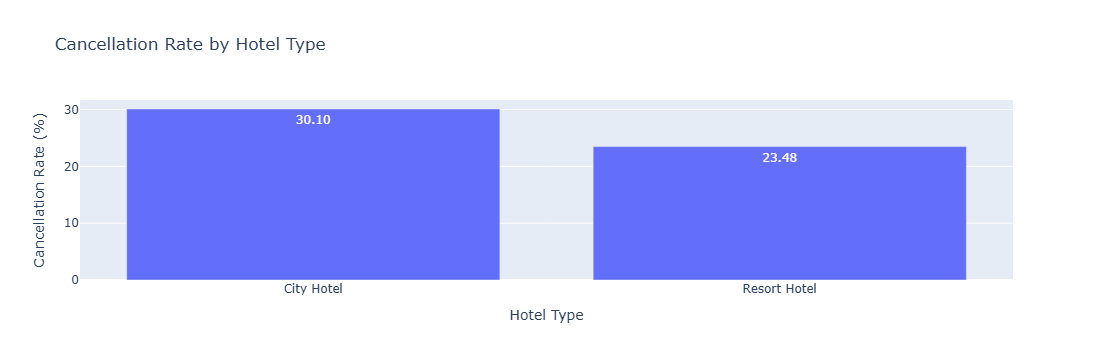

Observation: City Hotel has the higher cancellation rate at 30.10%.


In [8]:
hotel_rates = (
    df.groupby("hotel", observed=False)["is_canceled"]
      .mean()
      .mul(100)
      .reset_index(name="cancellation_rate")
)

fig = px.bar(
    hotel_rates,
    x="hotel",
    y="cancellation_rate",
    text_auto=".2f",
    title="Cancellation Rate by Hotel Type",
    labels={"hotel": "Hotel Type", "cancellation_rate": "Cancellation Rate (%)"}
)
fig.show()

highest_hotel = hotel_rates.loc[
    hotel_rates["cancellation_rate"].idxmax()
]

print(
    f"Observation: {highest_hotel['hotel']} has the higher cancellation rate "
    f"at {highest_hotel['cancellation_rate']:.2f}%."
)

## 9. Booking and Cancellation Trend Over Time

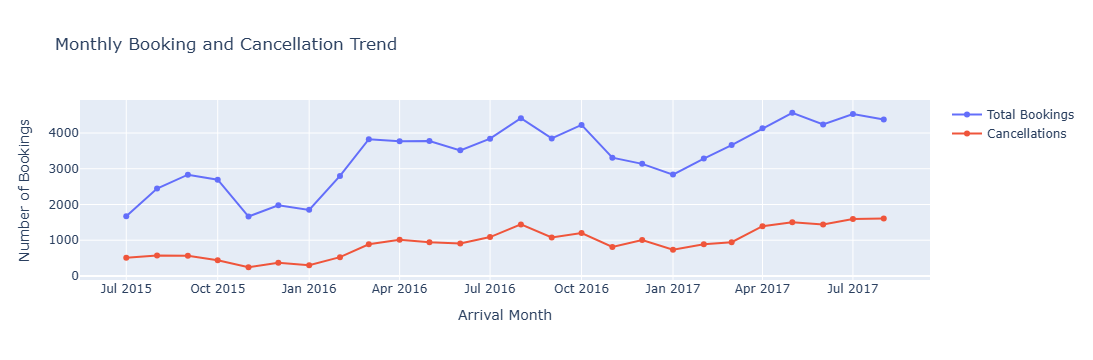

Observation: The highest booking volume occurred in 2017-05 with 4567 bookings.


In [9]:
monthly_trend = (
    df.dropna(subset=["arrival_date"])
      .assign(month=lambda x: x["arrival_date"].dt.to_period("M").astype(str))
      .groupby("month", observed=False)
      .agg(
          total_bookings=("is_canceled", "size"),
          cancellations=("is_canceled", "sum")
      )
      .reset_index()
)

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=monthly_trend["month"],
        y=monthly_trend["total_bookings"],
        mode="lines+markers",
        name="Total Bookings"
    )
)
fig.add_trace(
    go.Scatter(
        x=monthly_trend["month"],
        y=monthly_trend["cancellations"],
        mode="lines+markers",
        name="Cancellations"
    )
)
fig.update_layout(
    title="Monthly Booking and Cancellation Trend",
    xaxis_title="Arrival Month",
    yaxis_title="Number of Bookings"
)
fig.show()

peak_month = monthly_trend.loc[
    monthly_trend["total_bookings"].idxmax()
]

print(
    f"Observation: The highest booking volume occurred in {peak_month['month']} "
    f"with {int(peak_month['total_bookings'])} bookings."
)

## 10. Lead Time and Cancellation Behaviour

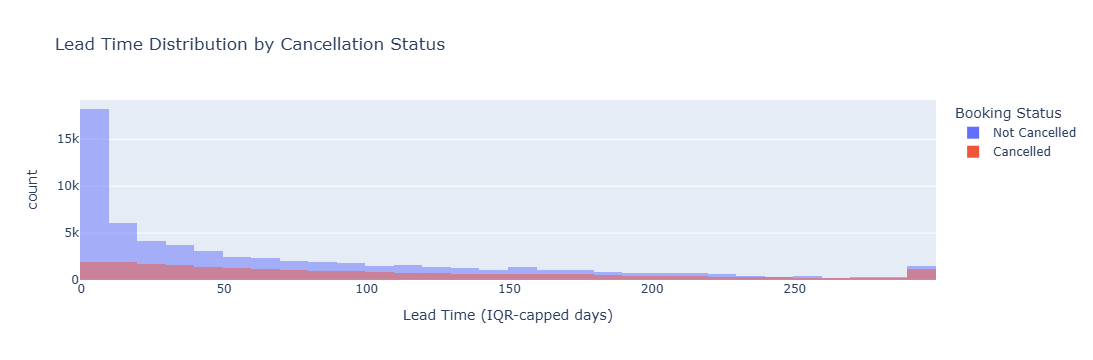

Observation: Average lead time is 105.74 days for cancelled bookings and 70.19 days for non-cancelled bookings.


In [10]:
fig = px.histogram(
    df,
    x="lead_time_clean",
    color="cancellation_status",
    barmode="overlay",
    nbins=40,
    title="Lead Time Distribution by Cancellation Status",
    labels={
        "lead_time_clean": "Lead Time (IQR-capped days)",
        "cancellation_status": "Booking Status"
    }
)
fig.show()

lead_time_means = (
    df.groupby("cancellation_status", observed=False)["lead_time"]
      .mean()
      .round(2)
)

print(
    "Observation: Average lead time is "
    f"{lead_time_means.get('Cancelled', np.nan):.2f} days for cancelled bookings "
    f"and {lead_time_means.get('Not Cancelled', np.nan):.2f} days for non-cancelled bookings."
)

## 11. ADR Distribution by Hotel Type

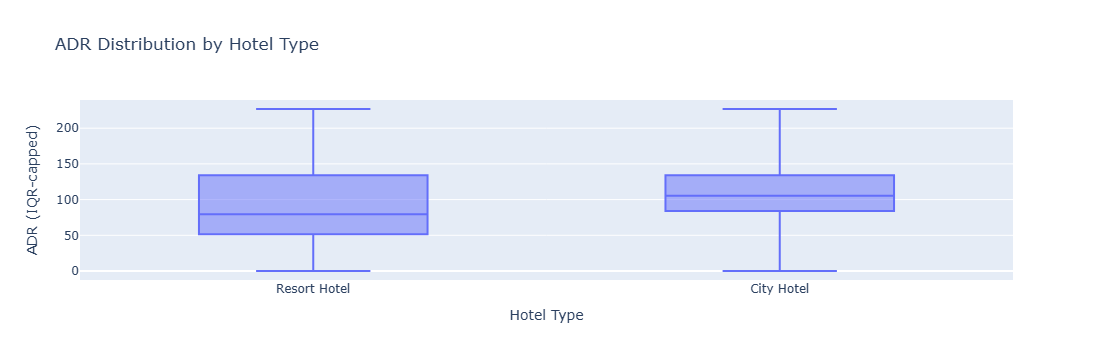

Observation: City Hotel has the higher median ADR at 105.30.


In [11]:
fig = px.box(
    df,
    x="hotel",
    y="adr_clean",
    points=False,
    title="ADR Distribution by Hotel Type",
    labels={"hotel": "Hotel Type", "adr_clean": "ADR (IQR-capped)"}
)
fig.show()

adr_medians = (
    df.groupby("hotel", observed=False)["adr"]
      .median()
      .sort_values(ascending=False)
)

print(
    f"Observation: {adr_medians.index[0]} has the higher median ADR "
    f"at {adr_medians.iloc[0]:.2f}."
)

## 12. Cancellation Rate by Market Segment — Cufflinks

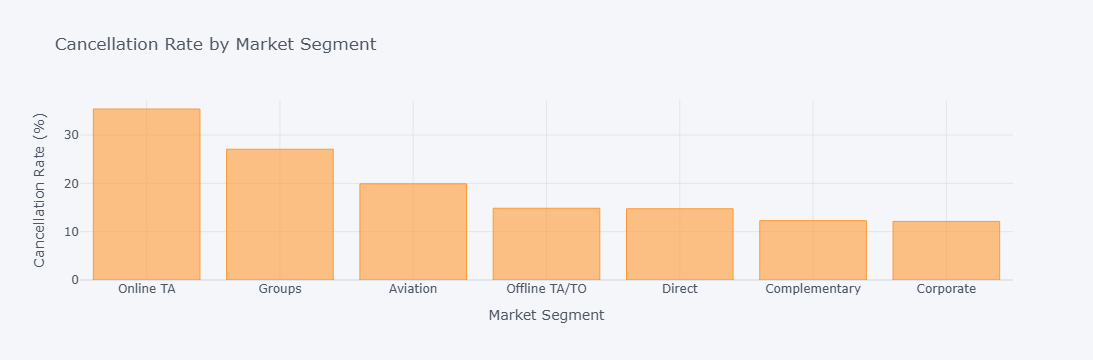

Observation: Among market segments with at least 100 bookings, Online TA has the highest cancellation rate at 35.38%.


In [12]:
segment_rates = (
    market_segment_summary[
        market_segment_summary["total_bookings"] >= 100
    ]
    .sort_values("cancellation_rate", ascending=False)
    .set_index("market_segment")[["cancellation_rate"]]
)

segment_fig = segment_rates.iplot(
    kind="bar",
    asFigure=True,
    title="Cancellation Rate by Market Segment",
    xTitle="Market Segment",
    yTitle="Cancellation Rate (%)"
)
segment_fig.show()

highest_segment = segment_rates["cancellation_rate"].idxmax()
highest_segment_rate = segment_rates.loc[
    highest_segment,
    "cancellation_rate"
]

print(
    f"Observation: Among market segments with at least 100 bookings, "
    f"{highest_segment} has the highest cancellation rate "
    f"at {highest_segment_rate:.2f}%."
)

## 13. Lead Time vs ADR

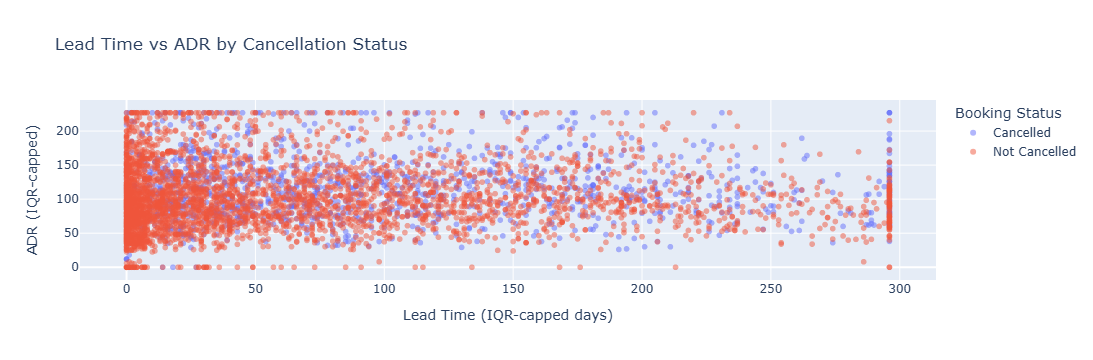

Observation: The correlation between lead time and ADR is 0.022, showing the strength and direction of their linear relationship.


In [13]:
scatter_df = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

fig = px.scatter(
    scatter_df,
    x="lead_time_clean",
    y="adr_clean",
    color="cancellation_status",
    opacity=0.5,
    title="Lead Time vs ADR by Cancellation Status",
    labels={
        "lead_time_clean": "Lead Time (IQR-capped days)",
        "adr_clean": "ADR (IQR-capped)",
        "cancellation_status": "Booking Status"
    }
)
fig.show()

lead_adr_corr = df[["lead_time", "adr"]].corr().iloc[0, 1]

print(
    f"Observation: The correlation between lead time and ADR is "
    f"{lead_adr_corr:.3f}, showing the strength and direction of their linear relationship."
)

## 14. Correlation Analysis

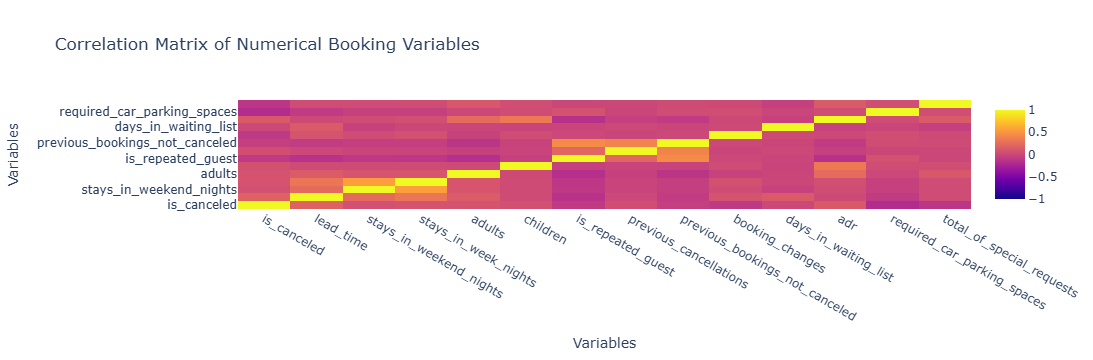

Observation: lead_time has the strongest linear relationship with cancellation among the selected numerical variables (correlation = 0.185).


In [14]:
correlation_columns = [
    "is_canceled",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

corr = df[correlation_columns].corr()

fig = go.Figure(
    data=go.Heatmap(
        z=corr.values,
        x=corr.columns,
        y=corr.index,
        zmin=-1,
        zmax=1
    )
)

fig.update_layout(
    title="Correlation Matrix of Numerical Booking Variables",
    xaxis_title="Variables",
    yaxis_title="Variables"
)
fig.show()

cancel_corr = (
    corr["is_canceled"]
    .drop("is_canceled")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

strongest_variable = cancel_corr.index[0]
strongest_value = cancel_corr.iloc[0]

print(
    f"Observation: {strongest_variable} has the strongest linear relationship "
    f"with cancellation among the selected numerical variables "
    f"(correlation = {strongest_value:.3f})."
)

## 15. Key Insights and Recommendations

In [15]:
highest_hotel_name = highest_hotel["hotel"]
highest_hotel_rate = highest_hotel["cancellation_rate"]

cancelled_profile = cancellation_profile.set_index("cancellation_status").loc["Cancelled"]
not_cancelled_profile = cancellation_profile.set_index("cancellation_status").loc["Not Cancelled"]

top_segment_name = highest_segment
top_segment_rate = highest_segment_rate

print("KEY INSIGHTS")
print(
    f"1. Overall cancellation rate is {overall_cancellation_rate:.2f}%."
)
print(
    f"2. {highest_hotel_name} has the highest hotel-level cancellation rate "
    f"at {highest_hotel_rate:.2f}%."
)
print(
    f"3. {top_segment_name} has the highest cancellation rate among market segments "
    f"with at least 100 bookings, at {top_segment_rate:.2f}%."
)
print(
    f"4. Cancelled bookings have an average lead time of "
    f"{cancelled_profile['average_lead_time']:.2f} days compared with "
    f"{not_cancelled_profile['average_lead_time']:.2f} days for non-cancelled bookings."
)
print(
    f"5. The highest booking volume occurred in {peak_month['month']} "
    f"with {int(peak_month['total_bookings'])} bookings."
)
print(
    f"6. Cancelled bookings average "
    f"{cancelled_profile['average_special_requests']:.2f} special requests, "
    f"compared with {not_cancelled_profile['average_special_requests']:.2f} "
    f"for non-cancelled bookings."
)

print("\nRECOMMENDATIONS")
print(
    f"1. Prioritise booking-confirmation and cancellation-reduction efforts for "
    f"{highest_hotel_name} and the {top_segment_name} market segment."
)
print(
    "2. Use additional confirmation reminders for bookings made far in advance, "
    "because lead time differs between cancelled and non-cancelled bookings."
)
print(
    f"3. Plan staffing and operational capacity around high-volume periods such as "
    f"{peak_month['month']}."
)
print(
    "4. Monitor cancellation rates together with ADR, customer type and special-request "
    "patterns when making pricing and customer-retention decisions."
)

KEY INSIGHTS
1. Overall cancellation rate is 27.52%.
2. City Hotel has the highest hotel-level cancellation rate at 30.10%.
3. Online TA has the highest cancellation rate among market segments with at least 100 bookings, at 35.38%.
4. Cancelled bookings have an average lead time of 105.74 days compared with 70.19 days for non-cancelled bookings.
5. The highest booking volume occurred in 2017-05 with 4567 bookings.
6. Cancelled bookings average 0.54 special requests, compared with 0.76 for non-cancelled bookings.

RECOMMENDATIONS
1. Prioritise booking-confirmation and cancellation-reduction efforts for City Hotel and the Online TA market segment.
2. Use additional confirmation reminders for bookings made far in advance, because lead time differs between cancelled and non-cancelled bookings.
3. Plan staffing and operational capacity around high-volume periods such as 2017-05.
4. Monitor cancellation rates together with ADR, customer type and special-request patterns when making pricing a

## 16. Close Database Connection

In [16]:
engine.dispose()
print("Database connection closed.")

Database connection closed.
